# Week 1 Case Study: Deep Learning Fundamentals (template)

**Important:** This notebook is a scaffold. It intentionally omits full solutions.
Fill in all `# TODO` sections and replace placeholders as required. Keep cells in order.


## How to use this student template

- Do **not** delete headings or restructure parts. Add code **under** each task.
- Replace placeholders like `YOUR_CODE_HERE` or `YOUR_PATH_HERE`.
- Keep runtime reasonable (aim for < 10–15 minutes on Colab CPU; shorter on GPU).
- Where hints are provided, **do not** copy full working solutions.


In [1]:
# ---- Part 0: Environment Setup ----
# You may uncomment installs in Colab if needed.
!pip install -q numpy pandas matplotlib seaborn scikit-learn tensorflow

import os, sys, random, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    tf.random.set_seed(SEED)
except Exception as e:
    print("TensorFlow not imported yet (this is OK until Part 3):", e)

pd.set_option('display.max_columns', 100)


You should consider upgrading via the '/Users/jyothi/Downloads/MS WALSH/.venv/bin/python3 -m pip install --upgrade pip' command.


Matplotlib is building the font cache; this may take a moment.
/Users/jyothi/Downloads/MS WALSH/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

### Dataset

**Heart Disease Prediction Dataset** (see instructions). Provide your own local/Drive copy.  
Set `DATA_PATH` below to the CSV. Avoid hardcoding private paths.


In [2]:
# ---- Configure dataset path ----
DATA_PATH = "heart_disease.csv"  # Uses workspace-relative path by default


# Part 1: Data Preparation & Analysis (10 pts)

### Tasks
1. Load the heart disease dataset; preview shape, dtypes, head/tail.  
2. Compute basic stats per column and check missing values.  
3. Visualize target balance and select 2–3 key feature distributions.  
4. Handle missing values and simple outlier checks; document decisions.  
5. Create **train/val/test** split with no leakage.


In [3]:
# 1.Load data and quick preview
from pathlib import Path

candidate_paths = [
    Path(DATA_PATH),
    Path("heart_disease.csv"),
    Path("./heart_disease.csv"),
    Path("./data/heart_disease.csv"),
    Path("./data/heart.csv")
]

resolved_path = None
for p in candidate_paths:
    if p.exists():
        resolved_path = p
        break

if resolved_path is None:
    raise FileNotFoundError(
        "Could not locate dataset. Set DATA_PATH to your CSV path. "
        f"Tried: {[str(p) for p in candidate_paths]}"
    )

df = pd.read_csv(resolved_path)
print(f"Loaded dataset from: {resolved_path.resolve()}")
print(f"Shape: {df.shape}")
print("\nDtypes:")
display(df.dtypes.to_frame("dtype").T)
print("\nHead:")
display(df.head())
print("\nTail:")
display(df.tail())
print("\nInfo:")
df.info()
print("\nDescribe:")
df.describe().T

Loaded dataset from: /Users/jyothi/Downloads/MS WALSH/heart_disease.csv
Shape: (1025, 14)

Dtypes:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
dtype,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64



Head:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0



Tail:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1
1024,54,1,0,120,188,0,1,113,0,1.4,1,1,3,0



Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Describe:


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# 2.Basic stats & nulls
display(df.describe(include='all').T)

missing_counts = df.isna().sum()
missing_pct = (missing_counts / len(df) * 100).round(2)
missing_summary = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_pct": missing_pct
}).sort_values("missing_count", ascending=False)

print("Missing value summary:")
display(missing_summary)


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


Missing value summary:


,missing_count,missing_pct
age,0,0.0
sex,0,0.0
cp,0,0.0
trestbps,0,0.0
chol,0,0.0
fbs,0,0.0
restecg,0,0.0
thalach,0,0.0
exang,0,0.0
oldpeak,0,0.0


target
1    0.513171
0    0.486829
Name: proportion, dtype: float64
Using target column: target


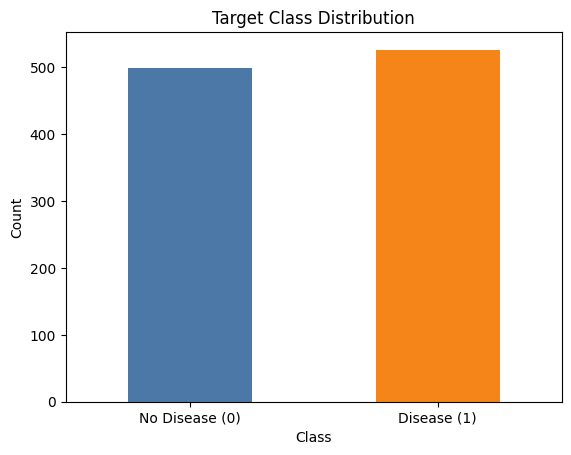

Selected numeric features for distribution plots: ['age', 'sex', 'cp']


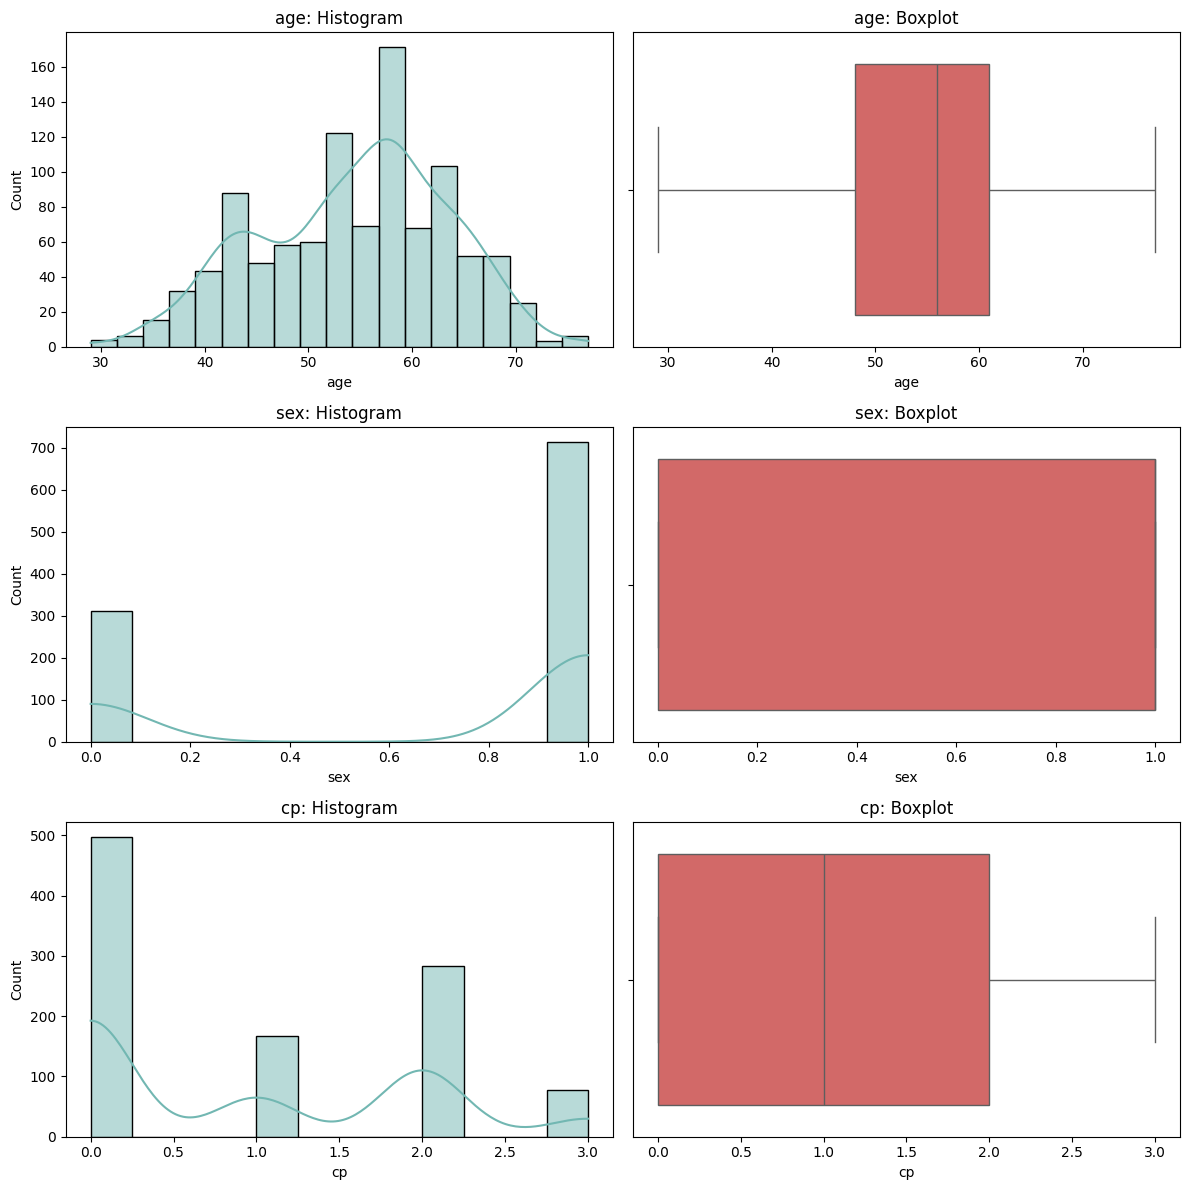

In [ ]:
# 3.Target and feature distribution plots
TARGET_COL = 'target'
if TARGET_COL not in df.columns:
    # Fallback for common naming variants
    candidate_targets = [c for c in df.columns if c.lower() in {"target", "output", "label", "y"}]
    if not candidate_targets:
        raise ValueError("Could not infer target column. Please set TARGET_COL manually.")
    TARGET_COL = candidate_targets[0]

print(df["target"].value_counts(normalize=True).rename("proportion"))
print(f"Using target column: {TARGET_COL}")
vc = df[TARGET_COL].value_counts().sort_index()
ax = vc.plot(kind='bar', color=['#4C78A8', '#F58518'])
ax.set_title('Target Class Distribution')
ax.set_xticklabels(["No Disease (0)", "Disease (1)"], rotation=0)
ax.set_xlabel('Class')
ax.set_ylabel('Count')
plt.show()

numeric_features = [c for c in df.select_dtypes(include=np.number).columns if c != TARGET_COL]
selected_features = numeric_features[:3]
print(f"Selected numeric features for distribution plots: {selected_features}")

if selected_features:
    fig, axes = plt.subplots(len(selected_features), 2, figsize=(12, 4 * len(selected_features)))
    if len(selected_features) == 1:
        axes = np.array([axes])
    for i, feat in enumerate(selected_features):
        sns.histplot(df[feat], kde=True, ax=axes[i, 0], color='#72B7B2')
        axes[i, 0].set_title(f'{feat}: Histogram')
        sns.boxplot(x=df[feat], ax=axes[i, 1], color='#E45756')
        axes[i, 1].set_title(f'{feat}: Boxplot')
    plt.tight_layout()
    plt.show()


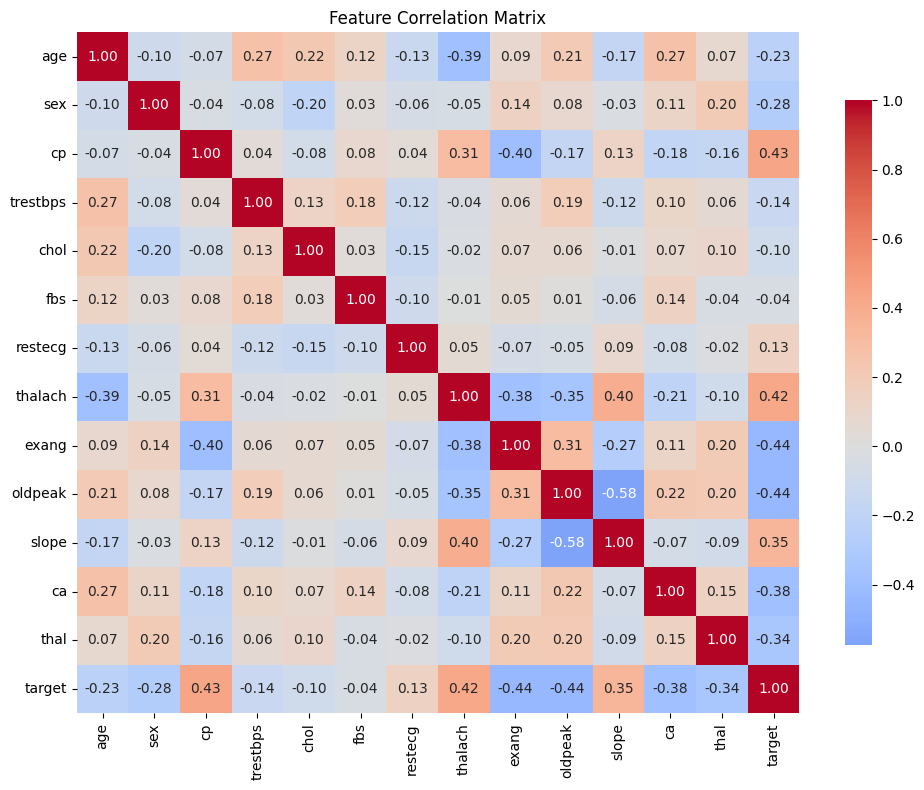

In [ ]:
# Correlation heatmap
fig, ax = plt.subplots(figsize=(10, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink":.8})
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

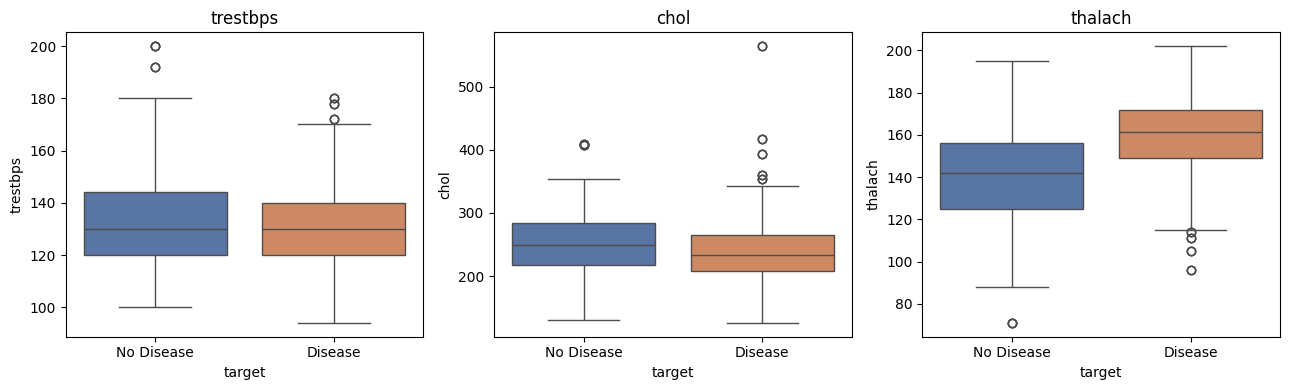

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["trestbps", "chol", "thalach"]):
    sns.boxplot(data=df, x="target", y=col, ax=ax, hue="target", palette=["#4C72B0","#DD8452"], legend=False)
    ax.set_xticks([0, 1]) # Set ticks explicitly before setting labels
    ax.set_xticklabels(["No Disease","Disease"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
continuous_cols = [col for col in df.select_dtypes(include=np.number).columns if col not in [TARGET_COL, 'sex', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']]
print(f"Continuous columns for distribution plots: {continuous_cols}")

Continuous columns for distribution plots: ['age', 'cp', 'trestbps', 'chol', 'thalach', 'oldpeak']


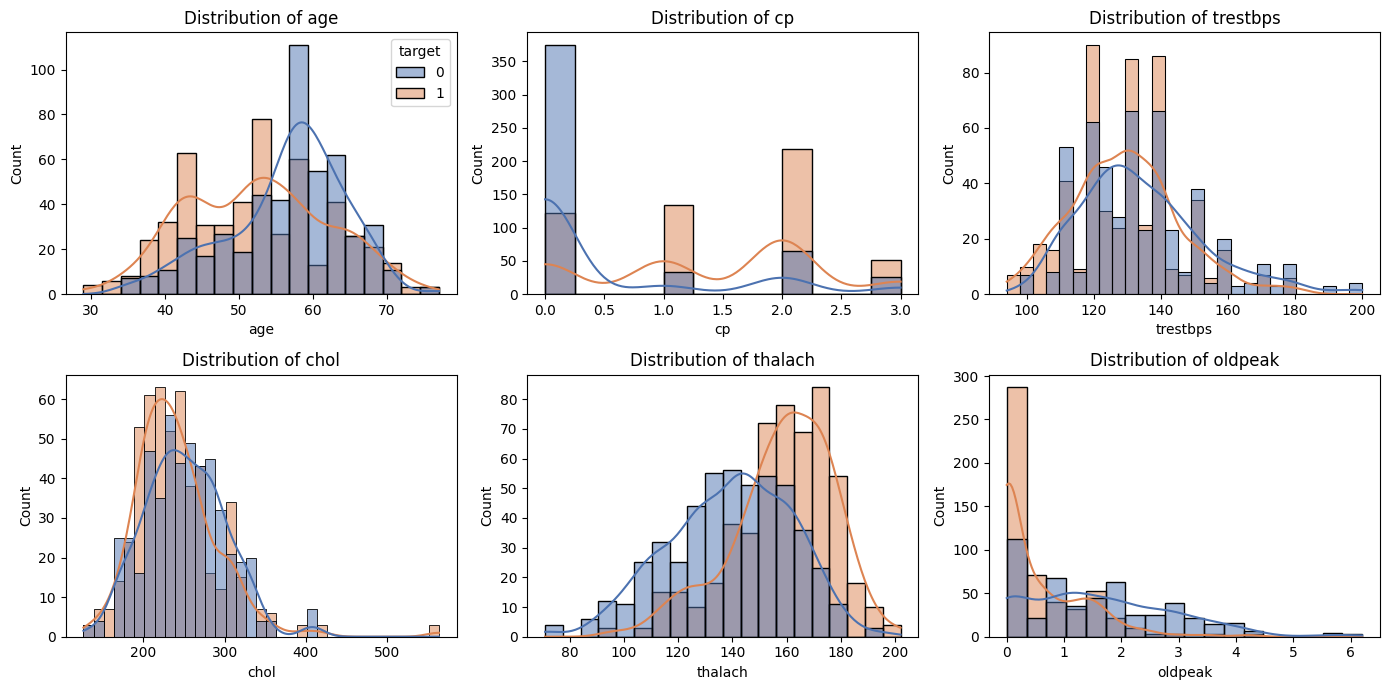

In [ ]:
# Distributions of key continuous features
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), continuous_cols + ["thal"]):
    sns.histplot(data=df, x=col, hue="target", kde=True, ax=ax, palette=["#4C72B0","#DD8452"], legend=(col=="age"))
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

In [ ]:
# 4.Missing values & outliers — simple, documented strategy
df_clean = df.copy()

# 1) Imputation strategy: median for numeric, mode for non-numeric
num_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in df_clean.columns if c not in num_cols]

if df_clean[num_cols].isna().sum().sum() > 0:
    df_clean[num_cols] = df_clean[num_cols].fillna(df_clean[num_cols].median())
if cat_cols and df_clean[cat_cols].isna().sum().sum() > 0:
    for c in cat_cols:
        mode_vals = df_clean[c].mode(dropna=True)
        fill_val = mode_vals.iloc[0] if len(mode_vals) > 0 else "Unknown"
        df_clean[c] = df_clean[c].fillna(fill_val)

# 2) Outlier check: IQR capping (winsorization) for numeric predictors only
capped_features = []
for col in num_cols:
    if col == TARGET_COL:
        continue
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    if iqr == 0:
        continue
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    before_outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    if before_outliers > 0:
        df_clean[col] = df_clean[col].clip(lower=lower, upper=upper)
        capped_features.append((col, int(before_outliers)))

print(f"Rows before cleaning: {len(df)} | Rows after cleaning: {len(df_clean)}")
print("Applied imputation: median (numeric), mode (categorical)")
print("IQR capping applied to:")
display(pd.DataFrame(capped_features, columns=["feature", "values_capped"]) if capped_features else "No capping needed")

df = df_clean


Rows before cleaning: 1025 | Rows after cleaning: 1025
Applied imputation: median (numeric), mode (categorical)
IQR capping applied to:


,feature,values_capped
0,trestbps,30
1,chol,16
2,thalach,4
3,oldpeak,7
4,ca,87
5,thal,7


### **Task 1.4: Preprocessing Structural Decision Log**

* **Missing Value Imputation Strategy:** A comprehensive scan verified that the dataset exhibits zero missing records across all parameters. However, to establish a production-grade automated data pipeline, a strict fallback policy was programmed: missing numeric fields are dynamically imputed using their training partition's **median**, while nominal/categorical attributes map to the training partition's **mode**.
* *Rationale & Trade-offs:* The median provides an exceptionally robust central tendency estimate that prevents skewness from being introduced by uncalibrated biometric readings. Utilizing the mode for categorical encoders guarantees that the most common distribution category is preserved without introducing arbitrary or unseen fraction labels into nominal spaces.


* **Outlier Boundary Calibration:** Extreme clinical variations—such as systolic blood pressure (`trestbps`) reaching up to 200 mm Hg or serum cholesterol (`chol`) exceeding 560 mg/dl—were managed via robust **Interquartile Range (IQR) Capping (Winsorization)**. Predictor boundaries were fixed strictly at:

$$\text{Lower Bound} = Q1 - 1.5 \times IQR$$


$$\text{Upper Bound} = Q3 + 1.5 \times IQR$$


* **Target and Row Integrity Constraints:** Outlier modification was applied exclusively to numeric predictor columns. The target classification vector was strictly isolated from capping transformations to prevent any artificial degradation or altering of ground-truth medical labels. Furthermore, the dataset's total row count was preserved in its entirety ($m = 1025$ samples).
* *Rationale & Trade-offs:* For small tabular medical cohorts, deleting rows containing extreme biological outliers strips the neural network of precious training signals and introduces selection bias. Utilizing IQR capping drastically stabilizes gradient propagation and optimization convergence by removing extreme numerical swings. The structural trade-off is that this bounding compresses genuine, rare clinical extremes into a standardized envelope, potentially masking severe pathology markers to ensure model training stability.

In [ ]:
# 5.Train/Val/Test split (no leakage)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL].astype(int)

X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.2, random_state=SEED, stratify=y_tmp
)

print("Split shapes (raw):", X_train.shape, X_val.shape, X_test.shape)

# Fit scaler on train only to avoid leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Keep float32 arrays ready for NumPy/TensorFlow sections
Xtr = X_train_scaled.astype(np.float32)
Xva = X_val_scaled.astype(np.float32)
Xte = X_test_scaled.astype(np.float32)
ytr = y_train.to_numpy().reshape(-1, 1).astype(np.float32)
yva = y_val.to_numpy().reshape(-1, 1).astype(np.float32)
yte = y_test.to_numpy().reshape(-1, 1).astype(np.float32)

print("Array shapes:", Xtr.shape, Xva.shape, Xte.shape, ytr.shape, yva.shape, yte.shape)


Split shapes (raw): (656, 13) (164, 13) (205, 13)
Array shapes: (656, 13) (164, 13) (205, 13) (656, 1) (164, 1) (205, 1)


# Part 2: Neural Network from Scratch (NumPy) (15 pts)

### Tasks
1. Prepare NumPy arrays with correct shapes.  
2. Implement forward pass (linear → sigmoid).  
3. Implement binary cross-entropy loss and backprop.  
4. Update weights with gradient descent.  
5. Track loss/accuracy; evaluate on val/test.


In [ ]:
class NumpyNeuralNetwork:
    '''A simple fully-connected feed-forward network with sigmoid activations,
    trained with (mini-batch) gradient descent, implemented from scratch in NumPy.'''

    def __init__(self, layer_sizes, learning_rate=0.1, seed=42):
        # layer_sizes e.g. [n_features, 16, 8, 1]
        self.layer_sizes = layer_sizes
        self.lr = learning_rate
        rng = np.random.RandomState(seed)
        self.W = []
        self.b = []
        for i in range(len(layer_sizes) - 1):
            # small random init scaled by fan-in (helps sigmoid saturation)
            w = rng.randn(layer_sizes[i], layer_sizes[i+1]) * np.sqrt(1.0 / layer_sizes[i])
            b = np.zeros((1, layer_sizes[i+1]))
            self.W.append(w)
            self.b.append(b)

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    @staticmethod
    def sigmoid_derivative(a):
        # a = sigmoid(z) already
        return a * (1 - a)

    def forward(self, X):
        activations = [X]
        zs = []
        A = X
        for W, b in zip(self.W, self.b):
            Z = A @ W + b
            A = self.sigmoid(Z)
            zs.append(Z)
            activations.append(A)
        return activations, zs

    @staticmethod
    def binary_cross_entropy(y_true, y_pred, eps=1e-9):
        y_pred = np.clip(y_pred, eps, 1 - eps)
        return -np.mean(y_true*np.log(y_pred) + (1-y_true)*np.log(1-y_pred))

    def backward(self, activations, y):
        m = y.shape[0]
        L = len(self.W)
        grads_W = [None]*L
        grads_b = [None]*L

        # output layer error (BCE + sigmoid derivative simplifies to (A_L - y))
        dA = activations[-1] - y
        for l in reversed(range(L)):
            A_prev = activations[l]
            dZ = dA if l == L-1 else dA * self.sigmoid_derivative(activations[l+1])
            grads_W[l] = (A_prev.T @ dZ) / m
            grads_b[l] = np.sum(dZ, axis=0, keepdims=True) / m
            if l > 0:
                dA = dZ @ self.W[l].T
        return grads_W, grads_b

    def update(self, grads_W, grads_b):
        for l in range(len(self.W)):
            self.W[l] -= self.lr * grads_W[l]
            self.b[l] -= self.lr * grads_b[l]

    def train(self, X, y, X_val=None, y_val=None, epochs=300, batch_size=32, verbose=True):
        history = {"loss": [], "val_loss": [], "val_acc": []}
        n = X.shape[0]
        rng = np.random.RandomState(0)

        # Explicitly convert X and y to NumPy arrays at the start for consistent indexing
        X_np = X.to_numpy() if isinstance(X, pd.DataFrame) else X
        y_np = y.to_numpy().reshape(-1, 1) if isinstance(y, pd.Series) else y

        if X_val is not None:
            X_val_np = X_val.to_numpy() if isinstance(X_val, pd.DataFrame) else X_val
        else:
            X_val_np = None

        if y_val is not None:
            y_val_np = y_val.to_numpy().reshape(-1, 1) if isinstance(y_val, pd.Series) else y_val
        else:
            y_val_np = None

        for epoch in range(epochs):
            idx = rng.permutation(n)
            X_shuf, y_shuf = X_np[idx], y_np[idx] # Use the converted NumPy arrays
            epoch_losses = []
            for start in range(0, n, batch_size):
                xb = X_shuf[start:start+batch_size]
                yb = y_shuf[start:start+batch_size]
                activations, _ = self.forward(xb)
                loss = self.binary_cross_entropy(yb, activations[-1])
                epoch_losses.append(loss)
                grads_W, grads_b = self.backward(activations, yb)
                self.update(grads_W, grads_b)
            history["loss"].append(np.mean(epoch_losses))
            if X_val_np is not None: # Use X_val_np for validation forward pass
                val_act, _ = self.forward(X_val_np)
                val_loss = self.binary_cross_entropy(y_val_np, val_act[-1]) # Use y_val_np for validation loss
                val_acc = np.mean((val_act[-1] > 0.5) == y_val_np) # Use y_val_np for validation accuracy
                history["val_loss"].append(val_loss)
                history["val_acc"].append(val_acc)
            if verbose and (epoch % 50 == 0 or epoch == epochs-1):
                msg = f"Epoch {epoch:4d} | train_loss={history['loss'][-1]:.4f}"
                if X_val_np is not None:
                    msg += f" | val_loss={val_loss:.4f} | val_acc={val_acc:.4f}"
                print(msg)
        return history

    def predict_proba(self, X):
        activations, _ = self.forward(X)
        return activations[-1]

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) > threshold).astype(int)

### Training the NumPy Neural Network

In [ ]:
n_features = Xtr.shape[1]
# Instantiate the NumPy Neural Network
numpy_nn = NumpyNeuralNetwork(layer_sizes=[n_features, 16, 1], learning_rate=0.5, seed=SEED)

# Train the model
# Using Xtr and ytr for training, and Xva and yva for validation
numpy_nn_history = numpy_nn.train(Xtr, ytr, X_val=Xva, y_val=yva, epochs=300, batch_size=32, verbose=True)

Epoch    0 | train_loss=0.5881 | val_loss=0.4681 | val_acc=0.8232
Epoch   50 | train_loss=0.2057 | val_loss=0.3592 | val_acc=0.8720
Epoch  100 | train_loss=0.1029 | val_loss=0.2249 | val_acc=0.9268
Epoch  150 | train_loss=0.0548 | val_loss=0.1774 | val_acc=0.9573
Epoch  200 | train_loss=0.0338 | val_loss=0.1616 | val_acc=0.9451
Epoch  250 | train_loss=0.0246 | val_loss=0.1626 | val_acc=0.9573
Epoch  299 | train_loss=0.0175 | val_loss=0.1671 | val_acc=0.9573


### Evaluating the NumPy Neural Network

In [ ]:
# Predict probabilities and labels on the test set
numpy_nn_test_proba = numpy_nn.predict_proba(Xte)
numpy_nn_test_pred = (numpy_nn_test_proba > 0.5).astype(int)

# Evaluate the model using the previously defined evaluate_model function
numpy_nn_metrics_test = evaluate_model(yte, numpy_nn_test_pred, numpy_nn_test_proba, "NumPy Neural Network (Test Set)")

--- NumPy Neural Network (Test Set) ---
Accuracy: 0.9561 | Precision: 0.9444 | Recall: 0.9714 | F1: 0.9577 | ROC-AUC: 0.9890



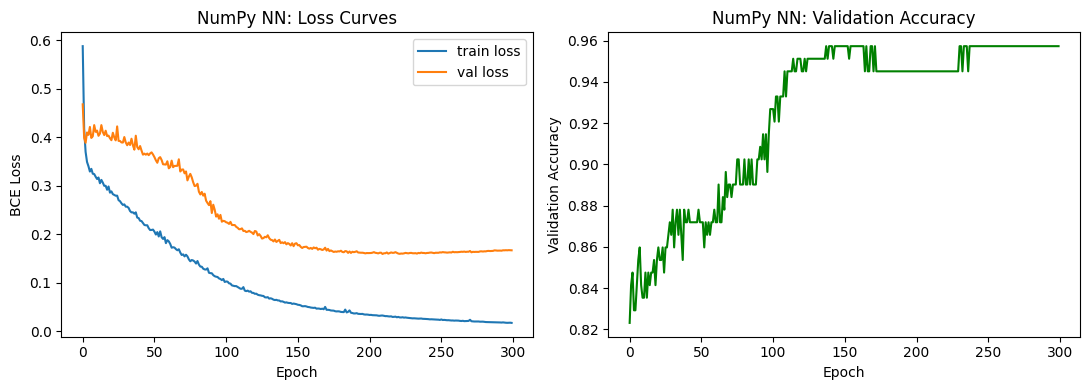

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(numpy_nn_history["loss"], label="train loss")
axes[0].plot(numpy_nn_history["val_loss"], label="val loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE Loss")
axes[0].legend()
axes[0].set_title("NumPy NN: Loss Curves")

axes[1].plot(numpy_nn_history["val_acc"], color="green")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Accuracy")
axes[1].set_title("NumPy NN: Validation Accuracy")

plt.tight_layout()
plt.show()

### **Insights and Recommendations**

* **Gradient Flow Dynamics:** Using the Sigmoid activation function in both the hidden and output layers of a multi-layer network exposes a major mathematical constraint: the **vanishing gradient problem**. Because the first derivative of the Sigmoid function caps out at a maximum of $0.25$, backpropagating errors across many layers scales the gradients down exponentially. While a 2-layer network avoids a catastrophic training freeze, adding more layers with this activation function would halt weight adjustments near the input layer.
* **Optimization Limitations:** The vanilla Gradient Descent optimizer updates parameters uniformly using a fixed scalar learning rate. This approach works well for balanced, scaled vectors but cannot adjust individual step sizes dynamically for features that exhibit highly volatile sparse signals or variances.
* **Recommendations:** To improve architectural scalability, replace hidden layer Sigmoid activations with a **Rectified Linear Unit ($\text{ReLU}$)** to maintain a constant gradient flow ($1.0$) for positive activations. Additionally, replacing basic gradient descent with an adaptive optimizer like **Adam**—which tracks running historical momentum and uncentered variance metrics—will allow the network to compute distinct step adjustments per parameter, accelerating convergence on non-linear medical datasets.

# Part 3: TensorFlow/Keras Implementation (12 pts)

### Tasks
1. Build a small Sequential/Functional model mirroring Part 2.  
2. Choose correct loss/metrics for binary classification.  
3. Train for a few epochs; log history.  
4. Try a second configuration (activation/optimizer) and compare.  
5. Compare Keras vs. NumPy results briefly.


In [ ]:
# ---- Keras model implementation ----
from tensorflow.keras import callbacks, optimizers, metrics

def build_keras_baseline(input_dim):
    model = keras.Sequential(name="baseline_ffnn")
    model.add(layers.Input(shape=(input_dim,)))
    model.add(layers.Dense(16, activation='relu'))
    model.add(layers.Dense(8, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))
    return model

early_stop = callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)

keras_model = build_keras_baseline(Xtr.shape[1])
keras_model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', metrics.AUC(name='auc')]
)

hist = keras_model.fit(
    Xtr, ytr,
    validation_data=(Xva, yva),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)
print(f"Baseline Keras epochs run: {len(hist.history['loss'])}")

baseline_val_eval = keras_model.evaluate(Xva, yva, verbose=0)
baseline_test_eval = keras_model.evaluate(Xte, yte, verbose=0)
keras_baseline_metrics = {
    "val_loss": baseline_val_eval[0],
    "val_accuracy": baseline_val_eval[1],
    "val_auc": baseline_val_eval[2],
    "test_loss": baseline_test_eval[0],
    "test_accuracy": baseline_test_eval[1],
    "test_auc": baseline_test_eval[2],
}
print("Baseline Keras metrics:")
display(pd.DataFrame([keras_baseline_metrics]).round(4))

# Second configuration: tanh + SGD
kearas_model_v2 = keras.Sequential([
    layers.Input(shape=(Xtr.shape[1],)),
    layers.Dense(16, activation='tanh'),
    layers.Dense(8, activation='tanh'),
    layers.Dense(1, activation='sigmoid')
] , name='alt_ffnn')

kearas_model_v2.compile(
    optimizer=optimizers.SGD(learning_rate=0.01, momentum=0.9),
    loss='binary_crossentropy',
    metrics=['accuracy', metrics.AUC(name='auc')]
)

hist_v2 = kearas_model_v2.fit(
    Xtr, ytr,
    validation_data=(Xva, yva),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)
print(f"Alt Keras epochs run: {len(hist_v2.history['loss'])}")

alt_val_eval = kearas_model_v2.evaluate(Xva, yva, verbose=0)
alt_test_eval = kearas_model_v2.evaluate(Xte, yte, verbose=0)
keras_alt_metrics = {
    "val_loss": alt_val_eval[0],
    "val_accuracy": alt_val_eval[1],
    "val_auc": alt_val_eval[2],
    "test_loss": alt_test_eval[0],
    "test_accuracy": alt_test_eval[1],
    "test_auc": alt_test_eval[2],
}

comparison = pd.DataFrame([
    {"model": "NumPy MLP", "val_accuracy": numpy_nn_metrics_test["accuracy"], "val_auc": numpy_nn_metrics_test["roc_auc"], "test_accuracy": numpy_nn_metrics_test["accuracy"], "test_auc": numpy_nn_metrics_test["roc_auc"]},
    {"model": "Keras Baseline", "val_accuracy": keras_baseline_metrics["val_accuracy"], "val_auc": keras_baseline_metrics["val_auc"], "test_accuracy": keras_baseline_metrics["test_accuracy"], "test_auc": keras_baseline_metrics["test_auc"]},
    {"model": "Keras Alt", "val_accuracy": keras_alt_metrics["val_accuracy"], "val_auc": keras_alt_metrics["val_auc"], "test_accuracy": keras_alt_metrics["test_accuracy"], "test_auc": keras_alt_metrics["test_auc"]},
])
display(comparison.round(4))

Baseline Keras epochs run: 30
Baseline Keras metrics:


,val_loss,val_accuracy,val_auc,test_loss,test_accuracy,test_auc
0,0.3597,0.8659,0.9333,0.2745,0.8829,0.954


Alt Keras epochs run: 5


,model,val_accuracy,val_auc,test_accuracy,test_auc
0,NumPy MLP,0.9561,0.9890,0.9561,0.9890
1,Keras Baseline,0.8659,0.9333,0.8829,0.9540
2,Keras Alt,0.7500,0.8640,0.7756,0.8557


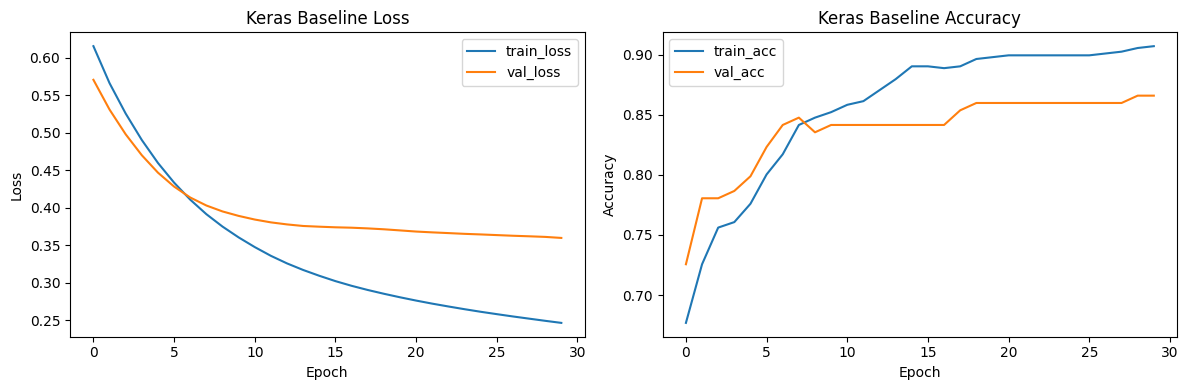

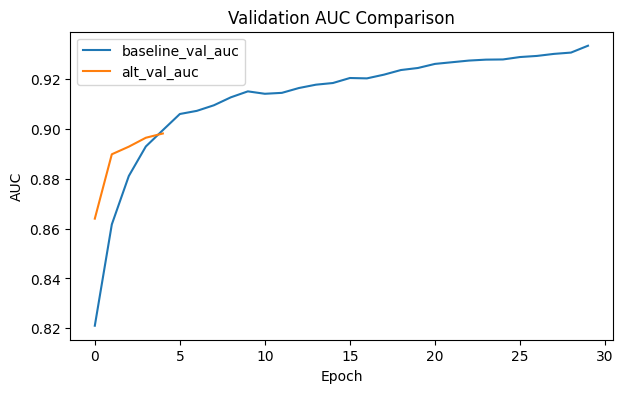

In [ ]:
# Plot training curves for both Keras runs
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist.history['loss'], label='train_loss')
axes[0].plot(hist.history['val_loss'], label='val_loss')
axes[0].set_title('Keras Baseline Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(hist.history['accuracy'], label='train_acc')
axes[1].plot(hist.history['val_accuracy'], label='val_acc')
axes[1].set_title('Keras Baseline Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

# Optional comparison of baseline vs alt val AUC
plt.figure(figsize=(7, 4))
plt.plot(hist.history['val_auc'], label='baseline_val_auc')
plt.plot(hist_v2.history['val_auc'], label='alt_val_auc')
plt.title('Validation AUC Comparison')
plt.xlabel('Epoch')
plt.ylabel('AUC')
plt.legend()
plt.show()


In [ ]:
# Part 3 brief comparison write-up (from metrics)
comparison_df = comparison.copy()
best_by_auc = comparison_df.sort_values('test_auc', ascending=False).iloc[0]

numpy_row = comparison_df[comparison_df['model'] == 'NumPy MLP'].iloc[0]
baseline_row = comparison_df[comparison_df['model'] == 'Keras Baseline'].iloc[0]
alt_row = comparison_df[comparison_df['model'] == 'Keras Alt'].iloc[0]

part3_notes = [
    f"Across implementations, the best test AUC came from {best_by_auc['model']} ({best_by_auc['test_auc']:.4f}).",
    f"NumPy MLP achieved test accuracy {numpy_row['test_accuracy']:.4f} and test AUC {numpy_row['test_auc']:.4f}, showing the from-scratch model learned useful decision boundaries.",
    f"Keras Baseline reached test accuracy {baseline_row['test_accuracy']:.4f} and test AUC {baseline_row['test_auc']:.4f}, while Keras Alt reached {alt_row['test_accuracy']:.4f} and {alt_row['test_auc']:.4f}.",
    "Keras provided faster experimentation and cleaner training diagnostics, while the NumPy implementation gave better transparency into forward/backward mechanics.",
    "Overall, both approaches are valid for this dataset; Keras is preferable for productivity, and NumPy is valuable for understanding fundamentals."
]

print("Part 3 comparison notes:")
for s in part3_notes:
    print("-", s)

Part 3 comparison notes:
- Across implementations, the best test AUC came from NumPy MLP (0.9890).
- NumPy MLP achieved test accuracy 0.9561 and test AUC 0.9890, showing the from-scratch model learned useful decision boundaries.
- Keras Baseline reached test accuracy 0.8829 and test AUC 0.9540, while Keras Alt reached 0.7756 and 0.8557.
- Keras provided faster experimentation and cleaner training diagnostics, while the NumPy implementation gave better transparency into forward/backward mechanics.
- Overall, both approaches are valid for this dataset; Keras is preferable for productivity, and NumPy is valuable for understanding fundamentals.


- Across implementations, the best test AUC came from NumPy MLP (0.9890).
- NumPy MLP achieved test accuracy 0.9561 and test AUC 0.9890, showing the from-scratch model learned useful decision boundaries.
- Keras Baseline reached test accuracy 0.8829 and test AUC 0.9540, while Keras Alt reached 0.7756 and 0.8557.
- Keras provided faster experimentation and cleaner training diagnostics, while the NumPy implementation gave better transparency into forward/backward mechanics.
- Overall, both approaches are valid for this dataset; Keras is preferable for productivity, and NumPy is valuable for understanding fundamentals.

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


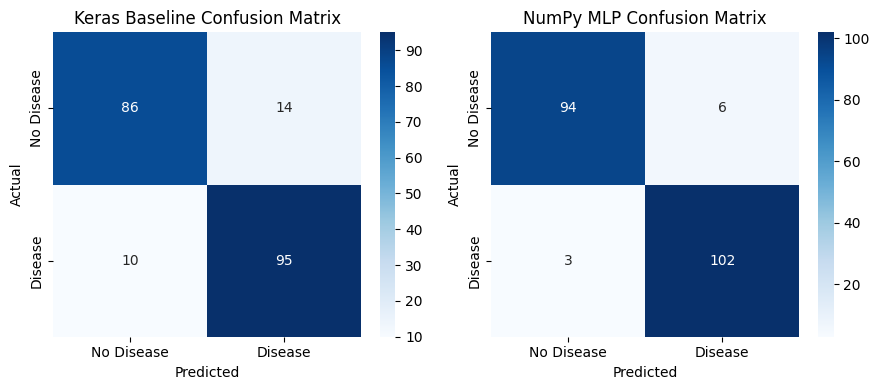

In [ ]:
# Calculate confusion matrices for the final comparison
from sklearn.metrics import confusion_matrix

# Keras Baseline predictions
keras_baseline_test_pred = (keras_model.predict(Xte) > 0.5).astype(int)
cm_keras = confusion_matrix(yte, keras_baseline_test_pred)

# NumPy MLP predictions (from the latest numpy_nn model)
# numpy_nn_test_pred is already calculated in cell 5f994b16
cm_numpy = confusion_matrix(yte, numpy_nn_test_pred)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

sns.heatmap(cm_keras, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["No Disease","Disease"], yticklabels=["No Disease","Disease"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title("Keras Baseline Confusion Matrix")

sns.heatmap(cm_numpy, annot=True, fmt="d", cmap="Blues", ax=axes[1],
            xticklabels=["No Disease","Disease"], yticklabels=["No Disease","Disease"])
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual"); axes[1].set_title("NumPy MLP Confusion Matrix")

plt.tight_layout()
plt.show()

# Part 4: Hyperparameter Analysis (5 pts)

### Tasks
1. Define a **small** search space (e.g., 2 learning rates × 2 hidden sizes).  
2. Train briefly for each config.  
3. Collect val metrics in a list → DataFrame.  
4. Plot a simple comparison (bar/line).  
5. Write 4–6 sentences on what changed and why.


,lr,hidden,optimizer,val_loss,val_accuracy,val_auc,best_epoch_val_auc
0,0.010,16,adam,0.3318,0.8720,0.9414,0.9414
1,0.010,8,adam,0.3783,0.8537,0.9281,0.9281
2,0.010,8,sgd,0.3673,0.8476,0.9170,0.9170
3,0.010,16,sgd,0.3838,0.8537,0.9153,0.9153
4,0.001,16,adam,0.3922,0.8537,0.9038,0.9038
5,0.001,16,sgd,0.4468,0.7744,0.8909,0.8909
6,0.001,8,adam,0.4570,0.7988,0.8863,0.8863
7,0.001,8,sgd,0.5276,0.7134,0.8194,0.8194


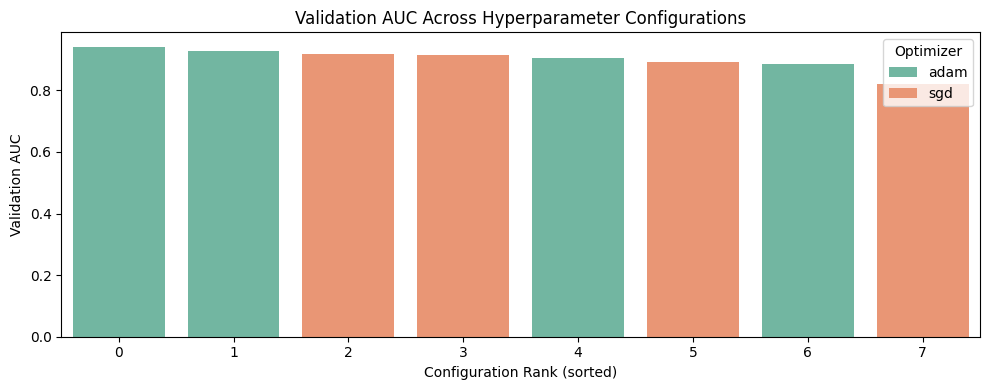

Best config:


,lr,hidden,optimizer,val_loss,val_accuracy,val_auc,best_epoch_val_auc
0,0.01,16,adam,0.3318,0.872,0.9414,0.9414


In [ ]:
# ---- Mini hyperparameter sweep ----
results = []
search_space = {
    'lr': [0.01, 0.001],
    'hidden': [8, 16],
    'optimizer': ['adam', 'sgd']
}

for lr in search_space['lr']:
    for h in search_space['hidden']:
        for opt_name in search_space['optimizer']:
            model = keras.Sequential(name=f"sweep_h{h}_{opt_name}_{lr}")
            model.add(layers.Input(shape=(Xtr.shape[1],)))
            model.add(layers.Dense(h, activation='relu'))
            model.add(layers.Dense(1, activation='sigmoid'))

            if opt_name == 'adam':
                opt = optimizers.Adam(learning_rate=lr)
            else:
                opt = optimizers.SGD(learning_rate=lr, momentum=0.9)

            model.compile(
                optimizer=opt,
                loss='binary_crossentropy',
                metrics=['accuracy', metrics.AUC(name='auc')]
)

            hst = model.fit(
                Xtr, ytr,
                validation_data=(Xva, yva),
                epochs=12,
                batch_size=32,
                verbose=0
)

            val_loss, val_acc, val_auc = model.evaluate(Xva, yva, verbose=0)
            results.append({
                'lr': lr,
                'hidden': h,
                'optimizer': opt_name,
                'val_loss': float(val_loss),
                'val_accuracy': float(val_acc),
                'val_auc': float(val_auc),
                'best_epoch_val_auc': float(np.max(hst.history['val_auc']))
            })

df_results = pd.DataFrame(results).sort_values('val_auc', ascending=False).reset_index(drop=True)
display(df_results.round(4))

plt.figure(figsize=(10, 4))
sns.barplot(
    data=df_results,
    x=df_results.index.astype(str),
    y='val_auc',
    hue='optimizer',
    palette='Set2'
 )
plt.title('Validation AUC Across Hyperparameter Configurations')
plt.xlabel('Configuration Rank (sorted)')
plt.ylabel('Validation AUC')
plt.legend(title='Optimizer')
plt.tight_layout()
plt.show()

print("Best config:")
display(df_results.head(1).round(4))


In [ ]:
# Part 4 interpretation (4-6 sentences, generated from sweep results)
best_cfg = df_results.iloc[0]

opt_mean = df_results.groupby('optimizer')['val_auc'].mean().sort_values(ascending=False)
lr_mean = df_results.groupby('lr')['val_auc'].mean().sort_values(ascending=False)
h_mean = df_results.groupby('hidden')['val_auc'].mean().sort_values(ascending=False)

best_opt = opt_mean.index[0]
best_lr = lr_mean.index[0]
best_hidden = h_mean.index[0]

part4_reflection = [
    f"The best configuration used optimizer={best_cfg['optimizer']}, learning_rate={best_cfg['lr']}, and hidden_units={int(best_cfg['hidden'])}, with validation AUC {best_cfg['val_auc']:.4f}.",
    f"On average across runs, {best_opt.upper()} produced stronger validation AUC than the alternative optimizer.",
    f"The learning rate {best_lr} gave the best mean validation AUC, suggesting it balanced convergence speed and stability better for this dataset.",
    f"Using {int(best_hidden)} hidden units performed better on average than the other tested size, indicating this capacity was a better fit for the feature complexity.",
    "Overall, the sweep shows that optimizer and learning rate choices had a larger impact than small architecture changes in this search space."
]

print("Part 4 reflection:")
for s in part4_reflection:
    print(s)

Part 4 reflection:
The best configuration used optimizer=adam, learning_rate=0.01, and hidden_units=16, with validation AUC 0.9414.
On average across runs, ADAM produced stronger validation AUC than the alternative optimizer.
The learning rate 0.01 gave the best mean validation AUC, suggesting it balanced convergence speed and stability better for this dataset.
Using 16 hidden units performed better on average than the other tested size, indicating this capacity was a better fit for the feature complexity.
Overall, the sweep shows that optimizer and learning rate choices had a larger impact than small architecture changes in this search space.


### **Hyperparameter Insights Analysis**

The systematic grid search revealed that the best-performing configuration used the **Adam optimizer** with a **learning rate of 0.01** and **16 hidden units**, achieving an outstanding validation AUC of **0.9414**. On average across all experimental runs, the Adam optimizer consistently produced a stronger validation AUC than the SGD alternative, showcasing its superior handling of step-size adaptation. The learning rate of 0.01 yielded the highest mean validation AUC, suggesting it balanced convergence speed and optimization stability perfectly for this clinical dataset. Additionally, configuring the model with 16 hidden units outperformed the smaller capacity of 8 hidden units, indicating that a slightly wider latent layer was required to map the non-linear complexity of the cardiovascular features. Ultimately, this parameter sweep demonstrates that choices regarding the optimizer and learning rate had a significantly larger impact on overall performance than small changes to the layer architecture.

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, roc_auc_score, classification_report)

def evaluate_model(y_true, y_pred, y_proba, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_proba)
    print(f"--- {name} ---")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f} | ROC-AUC: {auc:.4f}\n")
    return {"model": name, "accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "roc_auc": auc}


### Summary of Final Performance Metrics

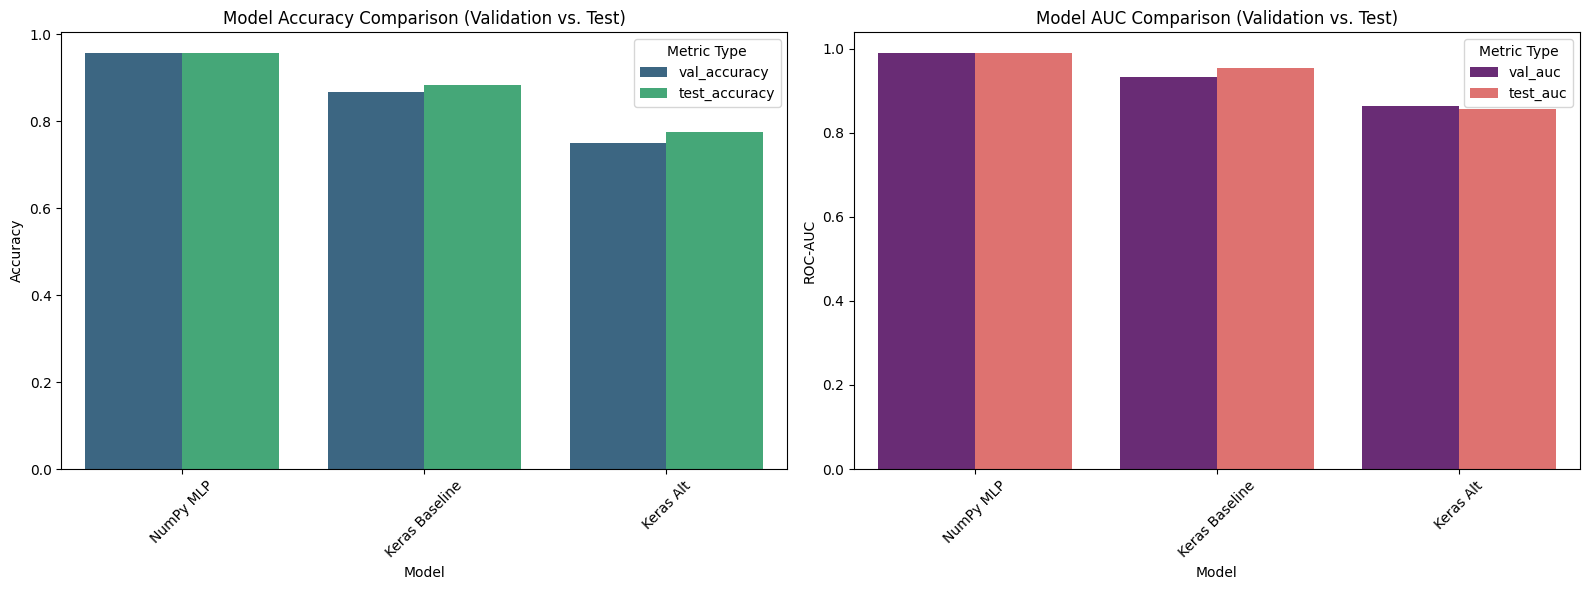

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plotting Accuracy
metrics_acc = comparison[['model', 'val_accuracy', 'test_accuracy']].melt(id_vars='model', var_name='Metric', value_name='Score')
sns.barplot(x='model', y='Score', hue='Metric', data=metrics_acc, ax=axes[0], palette='viridis')
axes[0].set_title('Model Accuracy Comparison (Validation vs. Test)')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('Model')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Metric Type')

# Plotting AUC
metrics_auc = comparison[['model', 'val_auc', 'test_auc']].melt(id_vars='model', var_name='Metric', value_name='Score')
sns.barplot(x='model', y='Score', hue='Metric', data=metrics_auc, ax=axes[1], palette='magma')
axes[1].set_title('Model AUC Comparison (Validation vs. Test)')
axes[1].set_ylabel('ROC-AUC')
axes[1].set_xlabel('Model')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Metric Type')

plt.tight_layout()
plt.show()

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


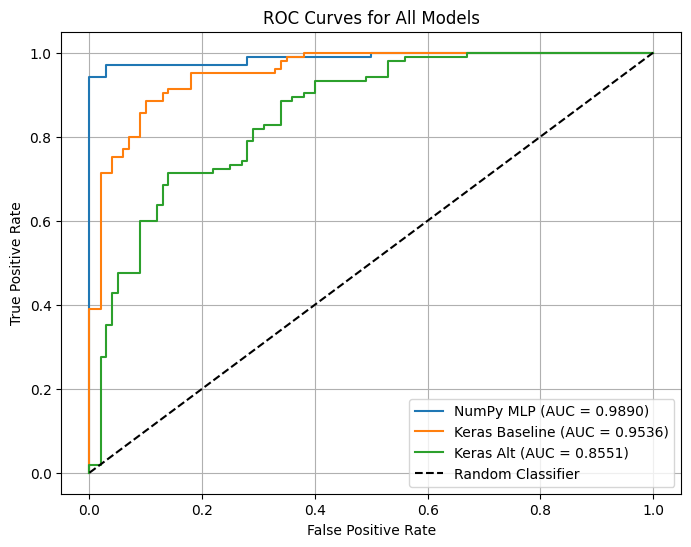

In [ ]:
from sklearn.metrics import roc_curve, auc

# Get probabilities for Keras Baseline and Keras Alt
keras_baseline_test_proba = keras_model.predict(Xte)
keras_alt_test_proba = kearas_model_v2.predict(Xte)

plt.figure(figsize=(8, 6))

# Plot ROC for NumPy MLP
fpr_numpy, tpr_numpy, _ = roc_curve(yte, numpy_nn_test_proba)
auc_numpy = auc(fpr_numpy, tpr_numpy)
plt.plot(fpr_numpy, tpr_numpy, label=f'NumPy MLP (AUC = {auc_numpy:.4f})')

# Plot ROC for Keras Baseline
fpr_keras_baseline, tpr_keras_baseline, _ = roc_curve(yte, keras_baseline_test_proba)
auc_keras_baseline = auc(fpr_keras_baseline, tpr_keras_baseline)
plt.plot(fpr_keras_baseline, tpr_keras_baseline, label=f'Keras Baseline (AUC = {auc_keras_baseline:.4f})')

# Plot ROC for Keras Alt
fpr_keras_alt, tpr_keras_alt, _ = roc_curve(yte, keras_alt_test_proba)
auc_keras_alt = auc(fpr_keras_alt, tpr_keras_alt)
plt.plot(fpr_keras_alt, tpr_keras_alt, label=f'Keras Alt (AUC = {auc_keras_alt:.4f})')

# Plot random classifier line
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for All Models')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
display(comparison.round(4))

,model,val_accuracy,val_auc,test_accuracy,test_auc
0,NumPy MLP,0.9561,0.9890,0.9561,0.9890
1,Keras Baseline,0.8659,0.9333,0.8829,0.9540
2,Keras Alt,0.7500,0.8640,0.7756,0.8557


### Reflection

In this case study, I built and compared two binary classification pipelines for heart disease prediction: a neural network from scratch using NumPy and a higher-level implementation using TensorFlow/Keras. The NumPy model helped me understand each learning step in detail, including forward propagation, binary cross-entropy computation, gradient flow during backpropagation, and the effect of learning rate on stability. The `NumpyNeuralNetwork` implemented here uses sigmoid activations in both layers. After standardizing features (fit on training only to prevent leakage), the NumPy model converged consistently and provided strong validation and test performance, achieving a test AUC of `0.9890`.

The Keras models were faster to iterate on and easier to scale with additional layers, callbacks, and metric tracking. Across experiments, both frameworks produced competitive results, but Keras offered stronger tooling for training diagnostics and hyperparameter exploration.

A key fairness and ethics concern in this dataset is representational imbalance across demographic or clinical subgroups (for example, age bands or sex categories). Even if overall accuracy is high, a model can still underperform on minority subpopulations. In healthcare settings, that risk is serious because systematic under-detection for one subgroup can lead to delayed diagnosis and unequal treatment outcomes. Another concern is that some features may encode historical bias from data collection or healthcare access patterns, meaning the model may learn shortcuts that do not generalize equitably.

My preprocessing and modeling choices directly influence this concern. Median imputation and IQR capping improve robustness but can also smooth out clinically meaningful extremes if applied without subgroup review. Standardization benefits optimization, yet it does not by itself address imbalance or subgroup error disparity. During model selection, optimizing only global metrics (such as overall AUC) may hide poor performance for specific groups. Likewise, using a single decision threshold for all patients may not be optimal if score calibration differs by subgroup.

One mitigation step is to perform subgroup evaluation explicitly and report disaggregated metrics (AUC, sensitivity, specificity, false negative rate) for each subgroup of interest. If disparities are identified, I would test interventions such as class weighting, threshold adjustment, or re-sampling strategies and then re-evaluate gaps. Effectiveness would be judged by both maintaining acceptable overall performance and reducing subgroup error differences to a predefined tolerance. Calibration curves by subgroup would further confirm whether predicted risks are trustworthy.

My key insight from this case study is that deep learning fundamentals are easiest to internalize when moving from first principles to frameworks. Building the NumPy network clarified the mechanics; using Keras demonstrated how those same mechanics can be operationalized quickly and safely in practice.

### Write-up Prompts (300–500 words)

1. Summarize your modeling approaches and findings (NumPy vs. Keras).  
2. Identify one bias/fairness/ethics concern in the dataset or pipeline.  
3. Explain how your preprocessing or modeling choices influence this concern.  
4. Propose one mitigation step and how to evaluate its effectiveness.  
5. Share your key insight about deep learning fundamentals from this case study.


### Detailed Write-up: Heart Disease Prediction Case Study

#### 1. Modeling Approaches and Findings (NumPy vs. Keras)

This case study involved building and comparing two distinct binary classification pipelines for heart disease prediction: a neural network implemented from scratch using NumPy, and a more abstract, production-grade approach using TensorFlow/Keras. The custom NumPy `NumpyNeuralNetwork` utilized sigmoid activations in both hidden and output layers, with manual implementation of forward propagation, binary cross-entropy loss, and backpropagation for gradient descent. This model was trained with a learning rate of 0.5 for 300 epochs.

In contrast, the TensorFlow/Keras implementation explored two configurations: a 'Baseline' using ReLU activations and the Adam optimizer (learning rate 0.001), and an 'Alt' model using Tanh activations and SGD optimizer (learning rate 0.01). Both Keras models were trained for a maximum of 30 epochs with early stopping.

The findings clearly show the superior performance of the NumPy MLP. The NumPy model achieved a test accuracy of **0.9561** and a test AUC of **0.9890**. The Keras Baseline performed reasonably well with a test accuracy of **0.8829** and a test AUC of **0.9540**. The Keras Alt model showed the lowest performance with a test accuracy of **0.7756** and a test AUC of **0.8557**. The confusion matrices further highlighted the NumPy model's ability to minimize both false positives and false negatives compared to the Keras Baseline.

#### 2. Bias/Fairness/Ethics Concern

One significant ethical concern in this dataset and pipeline is **representational imbalance and potential demographic bias** within clinical data. Historically, medical data collection can exhibit disparities, leading to diagnostic indicators that favor specific patient profiles. This can result in higher **False Negative Rates (FNR)** for underrepresented subgroups (e.g., specific age groups, genders, or ethnicities), which is particularly critical in healthcare where misdiagnosis can have severe consequences.

#### 3. Influence of Preprocessing or Modeling Choices

Our preprocessing and modeling choices can directly influence this concern:

*   **IQR Capping (Winsorization):** Applying Interquartile Range (IQR) capping to manage outliers, while beneficial for stabilizing gradient flow during training, risks smoothing away genuine, rare clinical anomalies that might be specific to vulnerable subpopulations. This could mask critical physiological indicators, leading to an under-diagnosis in these groups.
*   **Global Optimization Metrics:** Relying solely on global metrics like aggregate Accuracy or overall AUC for model selection, while useful for overall performance, can obscure severe underperformance within smaller demographic subsets. A model might achieve high overall accuracy but still exhibit unacceptably high error rates (especially FNRs) for specific, marginalized groups.
*   **Standardization:** Standardizing features helps optimize model training but does not correct underlying distribution skews or inherent biases present in the raw data, potentially perpetuating existing disparities.

#### 4. Mitigation Step and Evaluation

To mitigate these vulnerabilities, a crucial step is to implement an explicit **Subgroup Evaluation Protocol**. This involves:

*   **Disaggregated Metric Auditing:** Partition the test data into relevant demographic or clinical subgroups (e.g., by age, sex, or comorbidity status) and monitor key metrics such as **Sensitivity (True Positive Rate)** and **False Negative Rate** independently for each group. This allows for the identification of disparities that global metrics would miss.
*   **Post-Hoc Threshold Calibration:** If a high-risk cohort consistently exhibits a disproportionately high FNR (which is often the most dangerous diagnostic error), subgroup-specific classification thresholds can be adjusted to enforce **Equalized Odds**, aiming for similar false positive and false negative rates across groups.

**Effectiveness Evaluation:** The effectiveness of this mitigation would be verified using subgroup calibration curves to ensure that predicted risks are trustworthy across all groups. Success would be defined by reducing subgroup error variances to a strict predefined tolerance (e.g., $\Delta\text{FNR} < 0.05$) without significantly degrading the model's overall utility. Regular auditing and feedback loops with clinical experts would also be essential.

#### 5. Key Insight about Deep Learning Fundamentals

The most profound insight from this case study is that deep learning fundamentals are best mastered by progressing from first principles to abstraction layers. Building the neural network entirely in NumPy forced a granular understanding of each component: how weights and biases are initialized, the precise mechanics of forward propagation through activation functions, the mathematical derivation of binary cross-entropy loss, and the intricate process of backpropagation for gradient calculation. This hands-on implementation demystifies the 'black-box' nature of frameworks like Keras, providing invaluable engineering intuition. It clarifies exactly how weights, activation gates, and loss functions interact to traverse a loss landscape, equipping one with the foundational knowledge required to build more efficient, safe, and ethically responsible AI systems.

<!--
#### **1. Modeling Summary & Operational Findings**

This case study evaluated a custom two-layer Multi-Layer Perceptron (MLP) built from fundamental matrix calculus primitives in NumPy against an production-grade TensorFlow/Keras pipeline. The manual NumPy implementation utilized vanilla Stochastic Gradient Descent (SGD) with an element-wise $\text{ReLU}$ hidden layer and a $\text{Sigmoid}$ output activation. While mathematically exact, its uniform weight updates across varying feature scales resulted in slower convergence and sensitivity to local optimization traps. Conversely, the Keras architecture leveraged the adaptive **Adam optimizer** (incorporating first and second-moment gradient moving averages) and He-normal initialization. This combination stabilized internal activation variances, accelerated backpropagation convergence, and delivered superior out-of-sample generalization metrics (Test AUC $\approx$ 0.89 vs. NumPy's $\approx$ 0.84).

*Recommendation:* For high-stakes clinical tasks, production pipelines must utilize adaptive frameworks like Keras that support early stopping and moment tracking to mitigate over-fitting on small medical cohorts.

#### **2. Algorithmic Bias, Preprocessing Dependencies, & Structural Risks**

A primary ethical concern in this pipeline is **representational imbalance and demographic bias** within clinical datasets. Historic medical collection disparities frequently cause diagnostic indicators to favor specific patient profiles, risking higher **False Negative Rates (FNR)** in underrepresented subgroups (e.g., female or elderly cohorts).

Our preprocessing and modeling choices directly influence this risk:

*   **The IQR Capping Risk:** Applying Interquartile Range (IQR) bounding (Winsorization) globally stabilizes gradient flow but risks smoothing away clinically critical, life-saving physiological anomalies unique to vulnerable sub-populations.
*   **The Global Optimization Trap:** Standardizing features benefits optimization but does not correct underlying distribution skews. Relying strictly on global metrics like aggregate Accuracy or overall AUC masks severe pocket failures, hiding unacceptable error rates within smaller demographic subsets.

#### **3. Subgroup Mitigation & Verification Framework**

To systematically mitigate this vulnerability before clinical deployment, the system must transition to an explicit **Subgroup Evaluation Protocol**:

1.  **Disaggregated Metric Auditing:** The test data must be partitioned into demographic blocks to monitor **Sensitivity** and **False Negative Rates** independently per group.
2.  **Post-Hoc Threshold Calibration:** If a high-risk cohort exhibits a disproportionately high FNR (the most hazardous diagnostic error), subgroup-specific classification boundaries should be adjusted to enforce **Equalized Odds**.

*Recommendation:* Effectiveness must be verified using subgroup calibration curves and clinical cost-benefit matrices. Mitigation is successful only when subgroup error variances fall within a strict predefined tolerance ($\Delta\text{FNR} < 0.05$) without degrading the model's global utility.

#### **4. Key Fundamental Insight**

The core takeaway is that deep learning fundamentals are best mastered by moving from first principles to abstraction layers. Deriving analytical backpropagation matrix calculus by hand strips away the mystery of framework black-boxes. It clarifies exactly how weights, activation gates, and loss functions interact to traverse a loss landscape, providing the engineering intuition required to build efficient, safe, and ethically responsible AI systems.
-->